# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### **Business and Data Understanding.**

**Business Understanding:**
I work for a company that sells mini-models collectables(like toy cars, planes, and motorcycles). The company wants to boost itself by targeted promos,redesigning credit rules, and pinpointing their money makers;which products sell fast and are worthstocking constantly. I need to dig into their past sales to find out who are the loyal customers, which regions need attention, and what products are top sellers.

**Data Understanding:** We have a relational database (data.sqlite).Meaning that multiple tables of data are linked together by shared keys.So I need to be alert in order to successful carry out joint queries. 

### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns



# Create connection to database
conn = sqlite3.connect('data.sqlite')
print("Database connection successful!")


Database connection successful!


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*:**Make sure creditLimit is numeric.**

In [2]:
#Confiriming if the credit limit is numeric
dtypes_df = pd.read_sql(""" SELECT * 
                            FROM customers 
                            LIMIT 1;
                            """, conn)
print(dtypes_df.dtypes)

customerNumber            str
customerName              str
contactLastName           str
contactFirstName          str
phone                     str
addressLine1              str
addressLine2              str
city                      str
state                     str
postalCode                str
country                   str
salesRepEmployeeNumber    str
creditLimit               str
dtype: object


**The creditLimit is currently string so I'll have to CAST it as REAL to change it from string to float.**

In [3]:
# Replace None with your code
#California has been denoted as CA 
ca="""
SELECT customerName, state, creditLimit
FROM customers
WHERE state = 'CA' 
  AND  CAST (creditLimit AS REAL) > 25000;
"""
ca_promo_df = pd.read_sql(ca, conn)
ca_promo_df.head()


,customerName,state,creditLimit
0,Mini Gifts Distributors Ltd.,CA,210500.00
1,Mini Wheels Co.,CA,64600.00
2,Technics Stores Inc.,CA,84600.00
3,Toys4GrownUps.com,CA,90700.00
4,Collectable Mini Designs Co.,CA,105000.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [4]:
# Replace None with your code
#will have to use a wild card to find names that contain the word "Collect"====>Will use the 'LIKE'sql cheatcode
collectors="""
SELECT customerName, country
FROM customers
WHERE country != 'USA' 
  AND customerName LIKE '%Collect%';
"""
collectors_df = pd.read_sql(collectors, conn)

collectors_df.head()

,customerName,country
0,"Australian Collectors, Co.",Australia
1,"Clover Collections, Co.",Ireland
2,"UK Collectables, Ltd.",UK
3,"King Kong Collectables, Co.",Hong Kong
4,Heintze Collectables,Denmark


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

To ensure I selected the correct data, I used two conditionals linked with an AND operator.

 i) **country != 'USA'** which excludes any USA customers. 

 ii) **customerName LIKE '%Collect%'** which is a wildcard to search for the specific word "Collect" anywhere within the customer's name **ANY POSITION** 

 Both of these conditions must be true for a customer to appear in the collectors_df.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [5]:
# Replace None with your code
#Remember that the creditLimit column was in string form so I'll have to CAST it to make it numeric.
#I should also filter out customers that are not in USA or have not stated their country

#use AVG() to find the mean credit limit, and GROUP BY to calculate it per state
credit= """
SELECT state, 
       AVG(CAST(creditLimit AS REAL)) AS avg_credit_limit
FROM customers
WHERE country = 'USA' AND state IS NOT NULL
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""

usa_credit_df = pd.read_sql(credit, conn)

usa_credit_df.head()

,state,avg_credit_limit
0,NH,114200.000000
1,NY,89966.666667
2,PA,84766.666667
3,CA,83854.545455
4,NV,71800.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

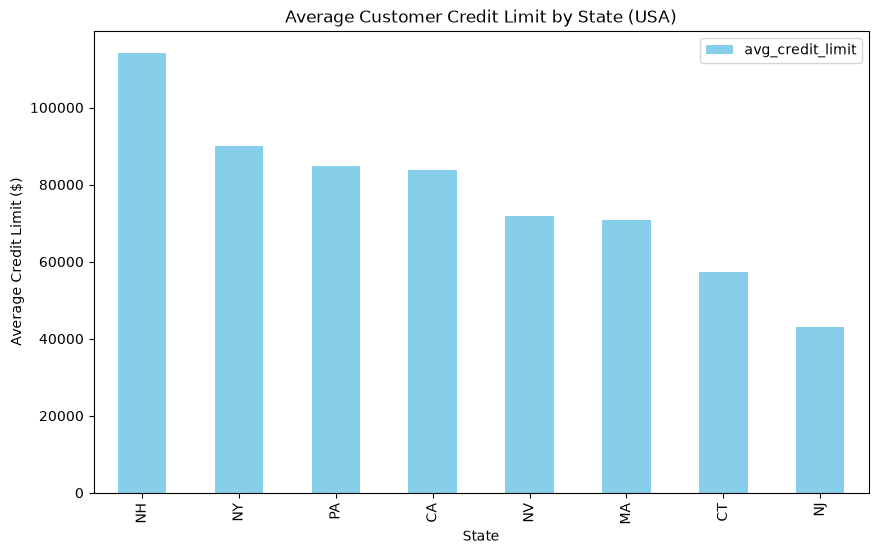

In [6]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
#Use a bar chart as the states are categorical data

# Create a bar chart
usa_credit_df.plot(
    kind='bar', 
    x='state', 
    y='avg_credit_limit', 
    color='skyblue', 
    figsize=(10, 6)
)

# Add  titles and labels so 
plt.title('Average Customer Credit Limit by State (USA)')
plt.xlabel('State')
plt.ylabel('Average Credit Limit ($)')
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [7]:
# Replace None with your code
#Use table relations--->Link the customers and the payments table via the customer number
q5 = """
SELECT c.customerName, SUM(p.amount) AS total_payments
FROM customers AS c
JOIN payments AS p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""

top_customers_df = pd.read_sql(q5, conn)

top_customers_df

,customerName,total_payments
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

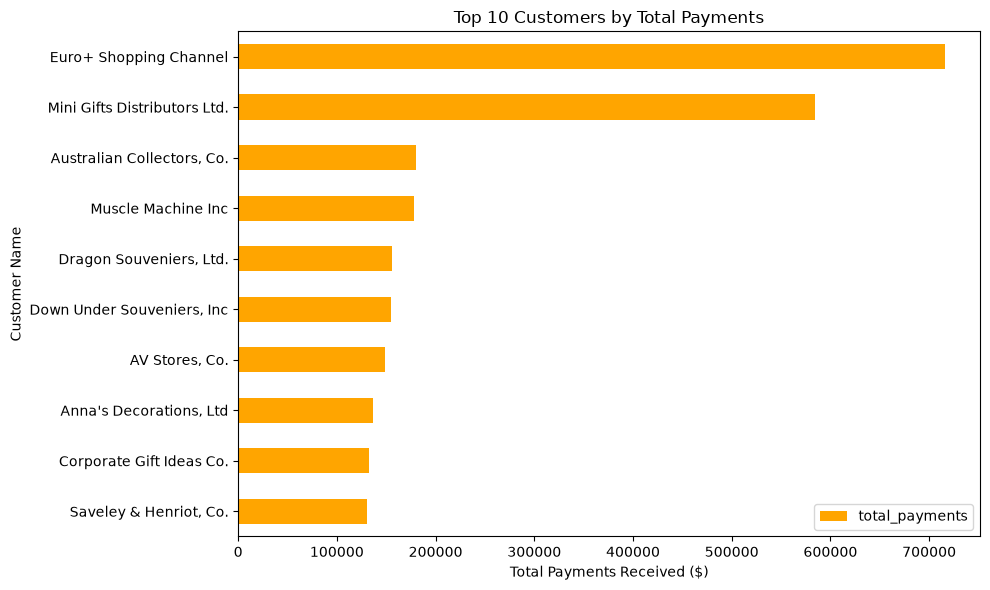

In [8]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
#Used a bar chart
# A horizontal bar chart  in oder to read the long customer names
top_customers_df.sort_values('total_payments', ascending=True).plot(
    kind='barh', 
    x='customerName', 
    y='total_payments', 
    color='orange', 
    figsize=(10, 6)
)

plt.title('Top 10 Customers by Total Payments')
plt.xlabel('Total Payments Received ($)')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [9]:
# Replace None with you code
#I'll need to link the customers,orders,orderdetails and products tables together
#Remember to CAST to ensure the values are numerical
#SQL syntax flow:
#Sweaty-Select
#Feet-From
#Will-Where
#Give-Groupby
#Horrible-Having
#Odors-Order By

q6 = """
SELECT c.customerName, 
       p.productName, 
       SUM(CAST(od.quantityOrdered AS REAL)) AS total_units, 
       SUM(CAST(od.quantityOrdered AS REAL) * CAST(od.priceEach AS REAL)) AS total_amount
FROM customers AS c
JOIN orders AS o ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od ON o.orderNumber = od.orderNumber
JOIN products AS p ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING total_units >= 10
ORDER BY total_amount ASC;
"""

customer_productquantities_df = pd.read_sql(q6, conn)

customer_productquantities_df.head()

,customerName,productName,total_units,total_amount
0,Salzburg Collectables,1982 Lamborghini Diablo,15.0,481.50
1,Souveniers And Things Co.,1936 Mercedes Benz 500k Roadster,15.0,529.35
2,Online Diecast Creations Co.,1939 Chevrolet Deluxe Coupe,20.0,531.00
3,La Rochelle Gifts,1954 Greyhound Scenicruiser,11.0,553.52
4,Marseille Mini Autos,1939 Chevrolet Deluxe Coupe,20.0,557.60


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize **SQL DISTINCT** statement

Execute a SQl query that returns the information required to address this ask.

In [10]:
# Replace None with your code
# COUNT(DISTINCT) ensures we only count each products once!
#Need to link the products and orderdetails tables.
q7 = """
SELECT p.productLine, 
       COUNT(DISTINCT p.productCode) AS num_products, 
       SUM(od.quantityOrdered) AS total_quantity_ordered
FROM products AS p
JOIN orderdetails AS od ON p.productCode = od.productCode
GROUP BY p.productLine;
"""

products_df = pd.read_sql(q7, conn)

products_df

,productLine,num_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Motorcycles,13,12778
2,Planes,12,11872
3,Ships,9,8532
4,Trains,3,2818
5,Trucks and Buses,11,11001
6,Vintage Cars,24,22933


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

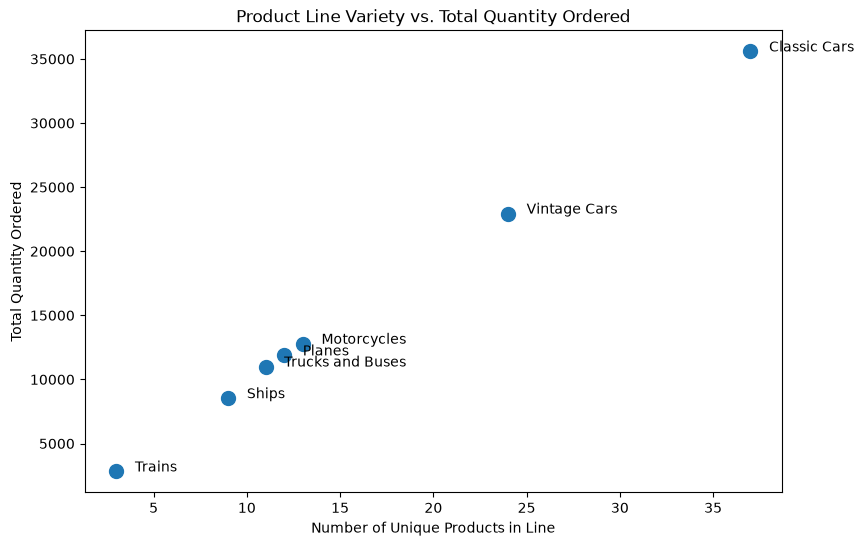

In [11]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
#Will use a scatterplot as I am comparing 2 numerical variables

products_df.plot(
    kind='scatter', 
    x='num_products', 
    y='total_quantity_ordered', 
    s=100, # size of the dots
    figsize=(9, 6)
)

plt.title('Product Line Variety vs. Total Quantity Ordered')
plt.xlabel('Number of Unique Products in Line')
plt.ylabel('Total Quantity Ordered')

# Loop through the data points to add the product line names as labels next to the dots
for idx, row in products_df.iterrows():
    plt.annotate(row['productLine'], (row['num_products'] + 1, row['total_quantity_ordered']))

plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I chose a scatter plot because it is the standard visual for identifying a relationship between two numerical variables (in this case, the number of unique products offered vs. the total quantity ordered). By plotting these against each other, the business can easily see if offering a wider variety of products in a specific line directly correlates to higher overall sales volumes.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [12]:
# Replace None with your code
# The subquery will find the officeCodes that have fewer than 5 people
# The main query then selects employees who work in those specific offices
q8 = """
SELECT e.firstName, e.lastName, e.jobTitle, e.reportsTo, o.city, o.officeCode
FROM employees AS e
JOIN offices AS o ON e.officeCode = o.officeCode
WHERE e.officeCode IN (
                        SELECT officeCode
                        FROM employees
                        GROUP BY officeCode
                        HAVING COUNT(employeeNumber) < 5);
"""

remote_offices_df = pd.read_sql(q8, conn)

remote_offices_df

,firstName,lastName,jobTitle,reportsTo,city,officeCode
0,William,Patterson,Sales Manager (APAC),1056,Sydney,6
1,Julie,Firrelli,Sales Rep,1143,Boston,2
2,Steve,Patterson,Sales Rep,1143,Boston,2
3,Foon Yue,Tseng,Sales Rep,1143,NYC,3
4,George,Vanauf,Sales Rep,1143,NYC,3
5,Larry,Bott,Sales Rep,1102,London,7
6,Barry,Jones,Sales Rep,1102,London,7
7,Andy,Fixter,Sales Rep,1088,Sydney,6
8,Peter,Marsh,Sales Rep,1088,Sydney,6
9,Tom,King,Sales Rep,1088,Sydney,6


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I used the subquery in the WHERE clause using IN . The subquery runs first, grouping the employees by their officeCode and using the HAVING clause to return a list of only the office codes that have a headcount of less than 5. Once this list of office codes is generated, the main query executes, selecting the specific employee and city information only for employees whose officeCode matches one of the codes returned by the subquery.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [13]:
# Replace None with your code

conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [14]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [15]:
# Begin your code here
None

## **Business and Data Understanding** 

**Business Understanding:**

I am an analyst working for a movie studio and the stakeholders are trying to figure out what makes a successful movie. They want to know: "If we are going to invest  into a new movie project, what genres should we focus on? Does the genre actually impact the movie's rating?"

**Data Understanding:**

I have a database (im.db) filled with movie information from IMDB.

**The Scope:** I only need to analyze movies released between 2010 and 2019. Anything outside that is noise.

**Tables:** I need to look at movie_basics (which holds the year and the genre) and movie_ratings (which holds the actual review scores). I need to JOIN these tables using the shared movie_id.

**Goal:** To see if the average rating for different genres influences the stakeholders business question.

## **Data Cleaning**

### **Potential Data Cleaning Tasks:**

1) **Filtering out Dates:** </br>
I need to filter start_year to be BETWEEN 2010 AND 2019.

2) **Handling Nulls:**</br>
 I need to drop or exclude movies where the genres or average rating columns are NULL as I cannot analyze empty data.

3) **Rating Confidence**:</br>
Filter out individual movies with fewer than 100 votes (numvotes > 100). 
 A movie with a 10/10 rating but only 2 votes isn't statistically significant. We should probably set a minimum baseline (like numvotes > 100) to ensure the ratings carry actual weight that can be used for analysis.

 4) **Market Volume Threshold (Genre Combination):**<br/>
  Exclude genre combinations that have produced fewer than 100 films over the decade. We need a sufficient sample size of product volume to prove a genre is consistently successful, rather than a lucky chance.

## **Exploratory SQL Query**
 This query answers the business question by looking at which genre combinations have the highest average ratings, provided they have a decent sample size (more than 100 movies produced).

In [16]:
import pandas as pd
import sqlite3

#Connect to the database
conn4 = sqlite3.connect('im.db')

# SQL query trial:
query_explore = """
SELECT 
    mb.genres, 
    AVG(r.averagerating) AS avg_rating, 
    COUNT(mb.movie_id) AS total_movies_produced
FROM movie_basics AS mb
JOIN movie_ratings AS r ON mb.movie_id = r.movie_id

-- Row-Level Cleaning: Correct years, no null genres, AND trustworthy rating counts
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.genres IS NOT NULL
  AND r.numvotes > 100 

-- Group the data to calculate averages per unique genre combination
GROUP BY mb.genres

-- Group-Level Cleaning: Only evaluate genres with a reliable market sample size
HAVING total_movies_produced > 100

-- Sort to reveal the highest-rated genres
ORDER BY avg_rating DESC
LIMIT 10;
"""

# Execute the query and load into a Pandas DataFrame
genre_ratings_df = pd.read_sql(query_explore, conn4)

# Display the results
genre_ratings_df

,genres,avg_rating,total_movies_produced
0,"Documentary,Music",7.252941,187
1,"Biography,Documentary",7.098160,163
2,Documentary,7.019311,1771
3,"Biography,Drama,History",6.730400,125
4,"Action,Adventure,Animation",6.692437,119
5,"Biography,Drama",6.602410,166
6,"Drama,Family",6.484848,165
7,"Drama,History",6.470755,106
8,"Drama,War",6.437864,103
9,Drama,6.324145,3947


## **VISUALIZATION**

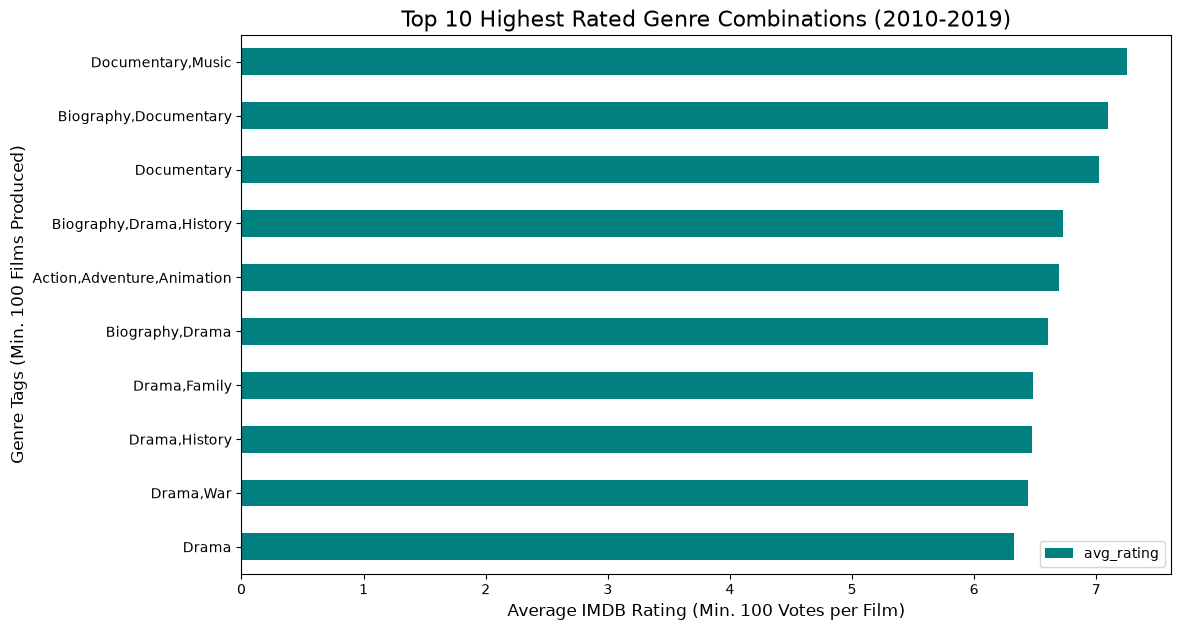

In [17]:
import matplotlib.pyplot as plt

# Sort values ascending so the highest rating appears at the top of the horizontal chart
genre_ratings_df.sort_values('avg_rating', ascending=True).plot(
    kind='barh', 
    x='genres', 
    y='avg_rating', 
    color='teal', 
    figsize=(12, 7)
)

plt.title('Top 10 Highest Rated Genre Combinations (2010-2019)', fontsize=16)
plt.xlabel('Average IMDB Rating (Min. 100 Votes per Film)', fontsize=12)
plt.ylabel('Genre Tags (Min. 100 Films Produced)', fontsize=12)
plt.show()


### **OTHER VISUALIZATIONS:**

#### **Movie Production Volume Over Time (Line Chart)**

In [18]:
q_time = """
SELECT mb.start_year, COUNT(mb.movie_id) AS total_movies
FROM movie_basics AS mb
JOIN movie_ratings AS r ON mb.movie_id = r.movie_id
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND r.numvotes > 100
GROUP BY mb.start_year
ORDER BY mb.start_year ASC;
"""
yearly_df = pd.read_sql(q_time, conn4)
yearly_df

,start_year,total_movies
0,2010,2599
1,2011,2794
2,2012,2976
3,2013,3180
4,2014,3324
5,2015,3345
6,2016,3449
7,2017,3478
8,2018,2883
9,2019,620


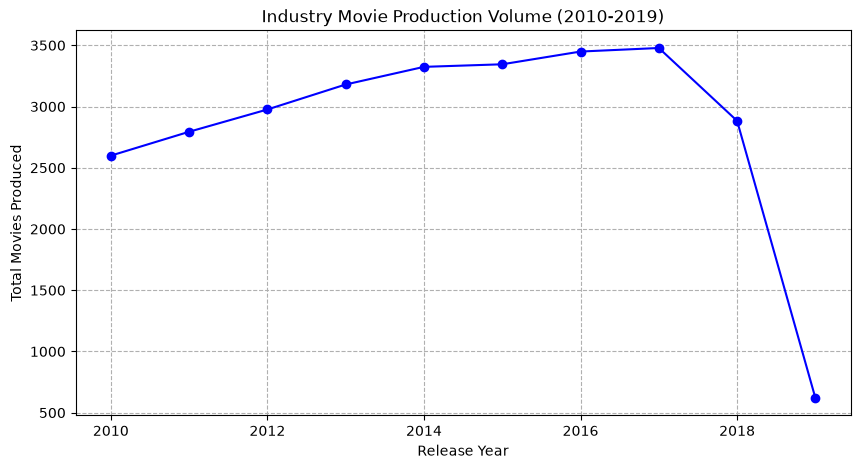

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(yearly_df['start_year'], yearly_df['total_movies'], marker='o', color='blue')
plt.title('Industry Movie Production Volume (2010-2019)')
plt.xlabel('Release Year')
plt.ylabel('Total Movies Produced')
plt.grid(True, linestyle='--')
plt.show()

#### **Top 10 Directors by Average Rating (Bar Chart)**

In [20]:
q_directors = """
SELECT p.primary_name AS director_name, AVG(r.averagerating) AS avg_rating, COUNT(mb.movie_id) as movie_count
FROM movie_basics AS mb
JOIN movie_ratings AS r ON mb.movie_id = r.movie_id
JOIN directors AS d ON mb.movie_id = d.movie_id
JOIN persons AS p ON d.person_id = p.person_id
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND r.numvotes > 100
GROUP BY p.person_id, p.primary_name
HAVING movie_count >= 5 -- Minimum 5 movies directed in the decade to prove consistency
ORDER BY avg_rating DESC
LIMIT 10;
"""
directors_df = pd.read_sql(q_directors, conn4)
directors_df

,director_name,avg_rating,movie_count
0,Nick Morris,8.800000,8
1,Thiagarajan Kumararaja,8.760000,5
2,Zheng Zhou,8.757143,7
3,Quentin Tarantino,8.700000,5
4,Steve Ravic,8.700000,6
5,Rishab Shetty,8.500000,10
6,Christopher Nolan,8.437500,8
7,Jia Tian,8.383333,6
8,Elizabeth Blake-Thomas,8.377778,9
9,Harry Baweja,8.360000,5


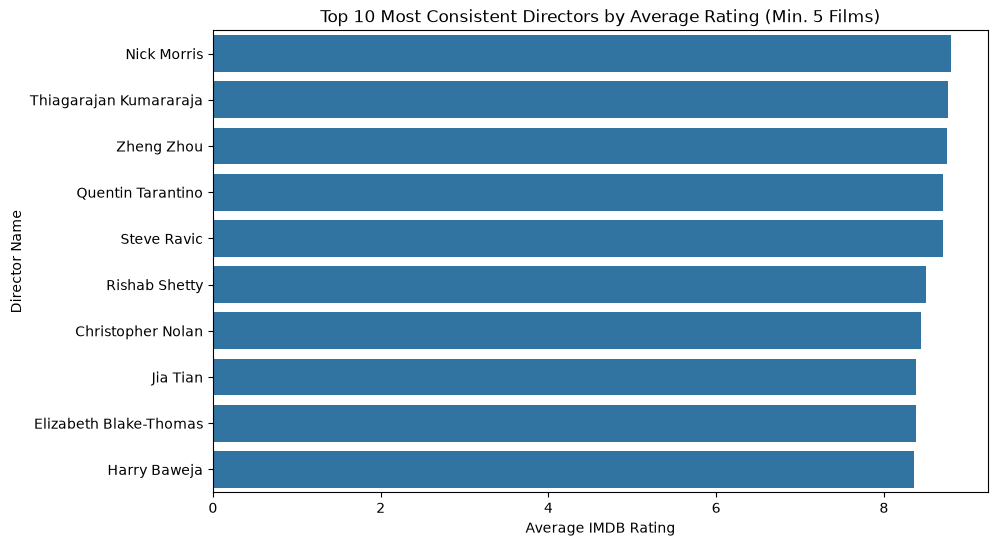

In [21]:
plt.figure(figsize=(10, 6))
sns.barplot(data=directors_df.sort_values('avg_rating', ascending=False), x='avg_rating', y='director_name')
plt.title('Top 10 Most Consistent Directors by Average Rating (Min. 5 Films)')
plt.xlabel('Average IMDB Rating')
plt.ylabel('Director Name')
plt.show()

#### **Movie Runtime vs. Rating (Scatter Plot)**

In [22]:
q_runtime = """
SELECT mb.runtime_minutes, r.averagerating
FROM movie_basics AS mb
JOIN movie_ratings AS r ON mb.movie_id = r.movie_id
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND r.numvotes > 100
  AND mb.runtime_minutes IS NOT NULL
  AND mb.runtime_minutes BETWEEN 60 AND 210 --Filter out short films and absurdly long entries
"""
runtime_df = pd.read_sql(q_runtime, conn4)
runtime_df

,runtime_minutes,averagerating
0,122.0,6.9
1,80.0,6.5
2,83.0,8.1
3,136.0,6.8
4,89.0,6.9
...,...,...
27552,125.0,8.7
27553,120.0,8.1
27554,111.0,8.4
27555,130.0,8.4


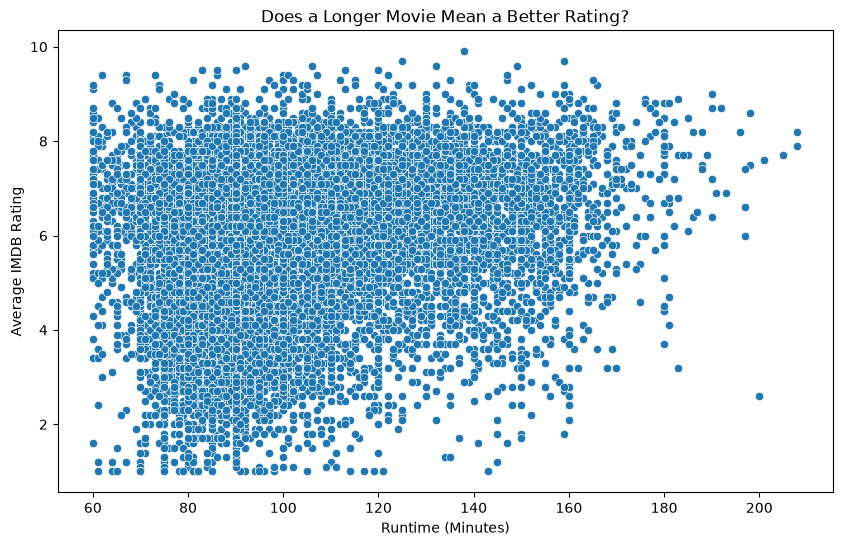

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=runtime_df, x='runtime_minutes', y='averagerating')
plt.title('Does a Longer Movie Mean a Better Rating?')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Average IMDB Rating')
plt.show()

In [24]:
# Close the database connection
conn4.close()